In [1]:
%pip install -q otter-grader
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


# Case Study 11A: Setting the Approval Threshold for a Credit Union's Small-Business Loans

**DS701 — Session 13 (Mon Oct 19, 2026) — Section A1**

[![](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tools4ds/DS701-Materials-FA26/blob/main/class_activity_notebooks/11A-InClass-Exercise-Logistic-Regression-A1/11A-InClass-Exercise-Logistic-Regression-A1.ipynb)

**Time: ~60 minutes.** Work in groups of 2-3.

Parts marked **(autograded)** are submitted to Gradescope; open-ended parts are graded
for participation. You may use AI assistance, but you must be able to explain and
justify every part of your solution when asked.

**Plan**

| Part | The lending desk's question | Method | Grading | Time |
|---|---|---|---|---|
| 1 | Build us a repayment score we can see inside — not a black box | Logistic regression from the likelihood: sigmoid, log-likelihood, one gradient step, then `sklearn` and the decision line | autograded | ~20 min |
| 2 | Above what probability of repayment should we approve automatically? | Accuracy against the prevalence, ROC-AUC, precision / recall / F1 across thresholds on a held-out split, then the expected-cost threshold $t^* = C_{FP}/(C_{FP}+C_{FN})$ | autograded | ~25 min |
| — | Report out: what you would tell the lending desk | team memo, then pair-share | participation | ~10 min |

Dependencies: `numpy`, `pandas`, `matplotlib`, `scikit-learn`.

## Case Study Setup

You are a data scientist on contract to the **small-business lending desk of a
Massachusetts credit union**. The desk lends a few thousand to a few hundred thousand
dollars to member businesses — a landscaper's second truck, a restaurant's build-out, a
contractor's payroll bridge. Today every application is read by a loan officer and the
queue is weeks long. The desk wants a **default-risk score** and, more than the score, a
**decision rule**: which applications to approve automatically — and before it sets that
cut it wants to understand what a false approval (a funded loan that defaults) and a false
decline (a sound member turned away) each cost it.

Member records cannot leave the credit union, so you cannot have the desk's data yet.
Instead you build a **simulator with the same shape as the desk's book** — applicant
attributes and a repaid/defaulted label — and prototype on that. Nothing below is a
member's data. Dataset 1 (Part 1) is deliberately simple: two attributes and a balanced
outcome, half repay and half default, so you can see the line the model draws. Dataset 2
(Part 2) is closer to the desk's book: five attributes and about one default in ten, the
rate the desk reports. The two cost figures in Part 2 are the desk's own rough estimates.
Because the applicants are simulated, the probabilities and dollar amounts you compute are
a prototype to reason with, not numbers to ship.

**What the lending desk asked you, and where you answer it**

1. *Build us a repayment score we can see inside — show us one step of how it is fitted, so
   we believe it is not a black box, and draw the line it puts through our applicants.*
   — Part 1
2. *Nine applicants in ten repay. Is accuracy the number to judge your score on? Above what
   probability of repayment should we approve automatically, and which mistake should we
   fear more?* — Part 2
3. *Which threshold do we ship, and what must we know before we trust it?* — Report out

Both datasets are synthetic, drawn from the seed below: Dataset 1 is 200 applicants with
two attributes; Dataset 2 is 2,000 applicants with five attributes. Both carry the label
**1 = repaid, 0 = defaulted**.

Run the next three cells as-is — everything below depends on them.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve

import warnings
warnings.filterwarnings("ignore")

In [5]:
# Lecture section. Only A1 runs this semester; this is kept because the build
# script reads it to name the variant directory the notebook is published in.
SECTION = "A1"
SEED = 701
rng = np.random.default_rng(SEED)


In [6]:
# Colab: fetch the autograder tests for this activity.
import os, sys, urllib.request

if "google.colab" in sys.modules:
    os.makedirs("tests", exist_ok=True)
    BASE = "https://raw.githubusercontent.com/tools4ds/DS701-Materials-FA26/main/class_activity_notebooks/11A-InClass-Exercise-Logistic-Regression-A1/tests/"
    for _q in ("q1", "q2", "q3", "q4", "q5", "q6"):
        urllib.request.urlretrieve(BASE + _q + ".py", "tests/" + _q + ".py")

In [7]:
# Initialize Otter
import otter
grader = otter.Notebook()

## Part 1: the repayment score, from the likelihood

**Why.** The desk's first question is whether the score is something they can see
inside. A logistic regression is: a linear score of the applicant's attributes, pushed
through a sigmoid to become a probability of repayment, fitted by climbing a likelihood
you can write down. In 1a you write that likelihood; in 1b you take one step of the climb
by hand — the step you will show the desk when they ask what "fitting" means; in 1c you
check the result against `scikit-learn` and draw the line the score puts through their
applicants.

**Dataset 1** — 200 simulated applicants, each described by two standardized attributes
$x_1, x_2$ (think years in business and a cash-flow coverage ratio), one Gaussian blob per
outcome. `X_pts` is `(n, 2)`; `y_cls` is **1 = repaid, 0 = defaulted**, so the model's $p$
is the probability of repayment. `X_design` prepends the column of ones for the intercept,
exactly as the lecture did with `df['intercept'] = 1.0`, so
$\boldsymbol{\beta} = (\beta_0, \beta_1, \beta_2)$ and the linear score of applicant $i$ is
`X_design[i] @ beta`.


Section A1: 200 points, 99 in class 1


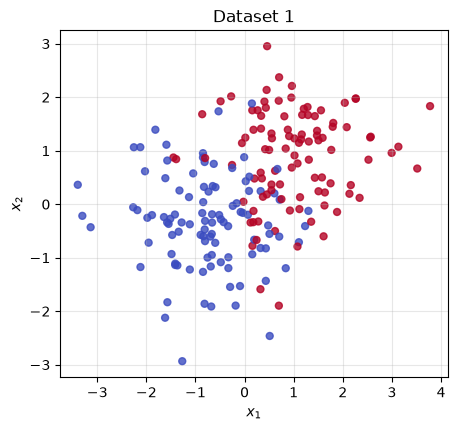

In [8]:
n_pts = 200
mu0 = np.array([-1.0, -0.5])
mu1 = np.array([1.0, 0.8])

y_cls = (rng.random(n_pts) < 0.5).astype(int)
X_pts = np.where(y_cls[:, None] == 1, mu1, mu0) + rng.normal(scale=1.0, size=(n_pts, 2))
X_design = np.column_stack([np.ones(n_pts), X_pts])      # (n, 3): [1, x1, x2]

print(f"Section {SECTION}: {n_pts} points, {y_cls.sum()} in class 1")
plt.figure(figsize=(5, 4.5))
plt.scatter(X_pts[:, 0], X_pts[:, 1], c=y_cls, cmap="coolwarm", s=25, alpha=0.8)
plt.xlabel("$x_1$"); plt.ylabel("$x_2$"); plt.title("Dataset 1"); plt.grid(alpha=0.3)
plt.show()


### 1a (autograded): sigmoid and log-likelihood

The lecture's model: the log-odds is linear, $\log\frac{p}{1-p} = \boldsymbol{\beta}^\top\mathbf{x}$, so
$p = \sigma(\boldsymbol{\beta}^\top\mathbf{x})$ with the **sigmoid** (inverse logit)
$\sigma(z) = \dfrac{1}{1+e^{-z}} = \dfrac{e^z}{1+e^z}$.

The likelihood of one observation is $p_i^{\,y_i}(1-p_i)^{1-y_i}$; for the whole dataset,
assuming independence, we take the product — or, in practice, the **sum of logs**:

$$\ell(\boldsymbol{\beta}) = \sum_i \big[\, y_i \log p_i + (1-y_i)\log(1-p_i) \,\big],
\qquad p_i = \sigma(\boldsymbol{\beta}^\top \mathbf{x}_i).$$

**Task.**

1. Write `sigmoid(z)` — must work elementwise on numpy arrays.
2. Write `log_likelihood(beta, X, y)` returning $\ell(\boldsymbol{\beta})$ as a Python `float`
   (`X` is a design matrix with the ones column, `y` is 0/1).
3. Evaluate it at `beta_init = [0, 1, -1]` and store the value in `ll_init`.

Sanity check you can do in your head: at $\boldsymbol{\beta} = 0$ every $p_i = 0.5$, so
$\ell(0) = n \log 0.5 \approx -0.693\,n$.


In [11]:
def sigmoid(z):
    """Inverse logit, elementwise."""
    return 1/ (1 + np.exp(-z))



def log_likelihood(beta, X, y):
    """Sum over i of y_i log p_i + (1 - y_i) log(1 - p_i), with p = sigmoid(X @ beta)."""
    p = sigmoid(X @ beta)
    return float(np.sum(y * np.log(p) + (1 - y) * np.log(1 - p)))


beta_init = np.array([0.0, 1.0, -1.0])
ll_init = log_likelihood(beta_init, X_design, y_cls)

print(f"log-likelihood at beta = 0        : {log_likelihood(np.zeros(3), X_design, y_cls):.3f}  (n log 0.5 = {n_pts * np.log(0.5):.3f})")
print(f"log-likelihood at beta_init       : {ll_init:.3f}")


log-likelihood at beta = 0        : -138.629  (n log 0.5 = -138.629)
log-likelihood at beta_init       : -149.425


In [10]:
grader.check("q1")

q1 results: All test cases passed!

### 1b (autograded): the gradient and one step of gradient ascent

There is no closed form for the maximizer of $\ell$, so the lecture climbs it:
$\boldsymbol{\beta}^{(t+1)} = \boldsymbol{\beta}^{(t)} + \alpha\, \nabla \ell(\boldsymbol{\beta}^{(t)})$.
The gradient of the log-likelihood has a famously tidy form (derive it later if you like —
differentiate $\ell$ and use $\sigma'(z) = \sigma(z)(1-\sigma(z))$):

$$\nabla \ell(\boldsymbol{\beta}) = X^\top (\mathbf{y} - \mathbf{p}), \qquad \mathbf{p} = \sigma(X\boldsymbol{\beta}).$$

Read it: each coordinate is a sum over points of *(residual) × (feature)* — the same
shape as the least-squares normal equations $X^\top(\mathbf{y} - X\boldsymbol{\beta})$ from last week,
with the sigmoid inside.

**Task.**

1. Write `grad_log_likelihood(beta, X, y)` returning the gradient as a length-3 array.
2. Take **one** step from `beta_init` with learning rate `LR = 0.01`; store it in
   `beta_step1` and its log-likelihood in `ll_step1`. It must be *higher* than `ll_init`.
3. Run the provided loop (`N_STEPS` steps of the same rule) to get `beta_ga`.


one step: -149.425 -> -84.235   (must go up)
beta after gradient ascent: [-0.6179  2.1212  1.4545]   log-lik -56.408


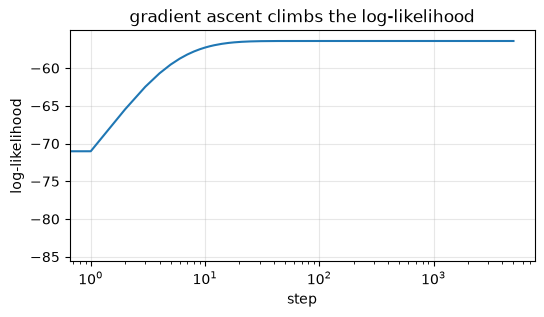

In [13]:
LR = 0.01
N_STEPS = 5000


def grad_log_likelihood(beta, X, y):
    """Gradient of the log-likelihood: X^T (y - sigmoid(X beta))."""
    return (y - sigmoid(X @ beta)) @ X


beta_step1 = beta_init + LR * grad_log_likelihood(beta_init, X_design, y_cls)
ll_step1 = log_likelihood(beta_step1, X_design, y_cls)
print(f"one step: {ll_init:.3f} -> {ll_step1:.3f}   (must go up)")

# The full climb (provided): repeat the same rule N_STEPS times.
beta_ga = beta_init.copy()
ll_trace = []
for _ in range(N_STEPS):
    beta_ga = beta_ga + LR * grad_log_likelihood(beta_ga, X_design, y_cls)
    ll_trace.append(log_likelihood(beta_ga, X_design, y_cls))

print("beta after gradient ascent:", np.round(beta_ga, 4), f"  log-lik {ll_trace[-1]:.3f}")
plt.figure(figsize=(6, 3))
plt.plot(ll_trace); plt.xscale("log")
plt.xlabel("step"); plt.ylabel("log-likelihood"); plt.title("gradient ascent climbs the log-likelihood")
plt.grid(alpha=0.3); plt.show()


In [14]:
grader.check("q2")

q2 results: All test cases passed!

### 1c (autograded): the same fit from scikit-learn, and the decision boundary

The desk's rule of thumb today is "approve if the applicant is more likely to repay than
not" — that is the $p = 0.5$ line you draw here. Part 2 asks whether it is the
right line.

**Task.**

1. Fit `LogisticRegression(penalty=None, max_iter=5000)` on `X_pts`, `y_cls` (sklearn adds
   the intercept itself — do *not* pass `X_design`). Store the fitted model in `clf_pts` and
   its coefficients as `beta_sk = [intercept, coef_1, coef_2]` (length-3 array).
2. `max_abs_diff` = the largest absolute difference between `beta_ga` and `beta_sk`.
   It should be tiny — two routes to the same maximum-likelihood estimate.
3. The **decision boundary** at threshold $0.5$ is where the log-odds is zero:
   $\beta_0 + \beta_1 x_1 + \beta_2 x_2 = 0$, a **straight line** in the plane.
   Solve for $x_2$ as a function of $x_1$ and store its slope in `boundary_slope` and its
   intercept in `boundary_intercept` (using `beta_sk`).
4. `train_acc` = training accuracy of `clf_pts` at threshold 0.5.

beta (gradient ascent): [-0.6179  2.1212  1.4545]
beta (sklearn)        : [-0.5612  1.8986  1.3149]   max |diff| = 2.23e-01
boundary: x2 = -1.444 x1 + 0.427;  train accuracy 0.870


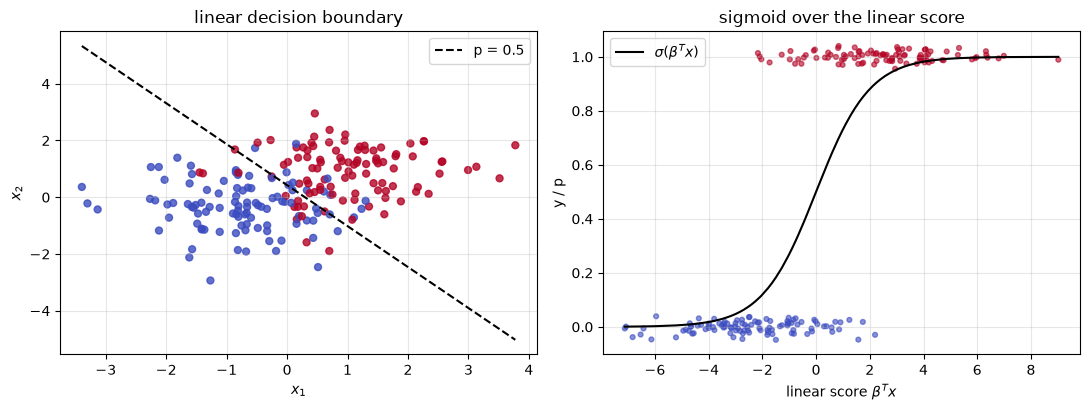

In [15]:
clf_pts = LogisticRegression(fit_intercept=True, solver="lbfgs", random_state=SEED)
beta_sk = clf_pts.fit(X_pts, y_cls).intercept_[0], *clf_pts.coef_[0]
max_abs_diff = np.max(np.abs(beta_ga - beta_sk))
boundary_slope = -beta_sk[1] / beta_sk[2]
boundary_intercept = -beta_sk[0] / beta_sk[2]
train_acc = accuracy_score(y_cls, clf_pts.predict(X_pts))

print("beta (gradient ascent):", np.round(beta_ga, 4))
print("beta (sklearn)        :", np.round(beta_sk, 4), f"  max |diff| = {max_abs_diff:.2e}")
print(f"boundary: x2 = {boundary_slope:.3f} x1 + {boundary_intercept:.3f};  train accuracy {train_acc:.3f}")

# Picture: the boundary in the plane, and the sigmoid over the linear score.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
xs = np.linspace(X_pts[:, 0].min(), X_pts[:, 0].max(), 50)
axes[0].scatter(X_pts[:, 0], X_pts[:, 1], c=y_cls, cmap="coolwarm", s=25, alpha=0.8)
axes[0].plot(xs, boundary_slope * xs + boundary_intercept, "k--", label="p = 0.5")
axes[0].set_xlabel("$x_1$"); axes[0].set_ylabel("$x_2$"); axes[0].legend(); axes[0].set_title("linear decision boundary")
score = X_design @ beta_sk
order = np.argsort(score)
axes[1].scatter(score, y_cls + np.random.default_rng(0).normal(scale=0.02, size=n_pts), c=y_cls, cmap="coolwarm", s=12, alpha=0.6)
axes[1].plot(score[order], sigmoid(score[order]), "k-", label="$\\sigma(\\beta^T x)$")
axes[1].set_xlabel("linear score $\\beta^T x$"); axes[1].set_ylabel("y / p"); axes[1].legend(); axes[1].set_title("sigmoid over the linear score")
for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


**Discuss (participation):** a loan officer looks at your left-hand plot and says: *"That is
just a straight line through our applicants — where is the probability you promised us?"*
Where exactly did the sigmoid go, and what does it give the desk that the line alone does not?

*(1-2 sentences here)*


In [16]:
grader.check("q3")

q3 results:
    q3 - 1 result:
        ❌ Test case failed
        Error at line 13 in test q3:
              assert max_abs_diff < 0.05, 'gradient ascent and sklearn should agree closely -- did the loop run to convergence?'
        AssertionError: gradient ascent and sklearn should agree closely -- did the loop run to convergence?

## Part 2: the threshold decision

**Why.** The desk's second question is the one it actually has to decide: above what
probability of repayment does an application get approved without a loan officer? The model
supplies the probability; the threshold is a decision about what the two mistakes cost. And
the desk's book is lopsided — about one applicant in ten defaults — which changes what
"a good score" means. In 2a you see why accuracy cannot judge the score on a book like this
and what ROC-AUC measures instead; in 2b you trace precision, recall and F1 across thresholds;
in 2c you let the desk's two cost figures choose the threshold.

**Dataset 2** — 2,000 simulated applicants, five standardized attributes (`LOAN_FEATURES`)
and the same label, **1 = repaid, 0 = defaulted**, drawn so that about 10% default. It is
split 50/50 into a **training half**, on which you fit, and a **held-out half**, on which
every number in Part 2 is computed: a threshold chosen on the applicants that fitted the
model would flatter it. `stratify=y_loan` keeps the default rate the same in both halves.

Throughout Part 2, **approve means $p \ge t$**, so an approval is the positive prediction:
*precision* is the fraction of approved applicants who repay, and *recall* is the fraction of
members who would repay that you approve.

In [17]:
n_loan = 2000
LOAN_FEATURES = ["years_in_business", "cash_flow_coverage", "credit_score", "debt_to_income", "loan_to_revenue"]
w_loan = np.array([0.6, 0.9, 0.8, -0.6, -0.5])     # the simulator's true effects on the log-odds of repaying

X_loan = rng.normal(size=(n_loan, len(LOAN_FEATURES)))
p_loan = 1 / (1 + np.exp(-(3.0 + X_loan @ w_loan)))
y_loan = (rng.random(n_loan) < p_loan).astype(int)

X_loan_train, X_loan_test, y_loan_train, y_loan_test = train_test_split(
    X_loan, y_loan, test_size=0.5, stratify=y_loan, random_state=SEED)

print(f"Section {SECTION}: {n_loan} applicants, {1 - y_loan.mean():.1%} defaulted")
print(f"training half: {len(y_loan_train)}   held-out half: {len(y_loan_test)} "
      f"({(y_loan_test == 0).sum()} defaults, {(y_loan_test == 1).sum()} repaid)")

Section A1: 2000 applicants, 9.9% defaulted
training half: 1000   held-out half: 1000 (99 defaults, 901 repaid)


### 2a (autograded): accuracy's floor, and what AUC measures

The lecture warned that **accuracy has a floor set by the prevalence**: a "score" that
approves every applicant is right whenever the applicant repays, without looking at a single
attribute. The **ROC curve** plots the true-positive rate against the false-positive rate,
one point per threshold, and its **AUC** is a threshold-free summary of how well the model
*ranks* repayers above defaulters.

**Task.**

1. Fit `clf_loan = LogisticRegression(penalty=None, max_iter=1000)` on the training half.
2. `p_test` = its predicted probability of repayment for each held-out applicant
   (`predict_proba(...)[:, 1]`).
3. `acc_floor` = the held-out accuracy of approving **everyone**; `acc_05` = the held-out
   accuracy of `clf_loan` at threshold 0.5 (approve when `p_test >= 0.5`). Both `float`.
4. `auc_test` = `roc_auc_score(y_loan_test, p_test)` as a `float`.

approve everyone : accuracy 0.901
clf_loan at 0.5  : accuracy 0.913
ROC-AUC          : 0.830


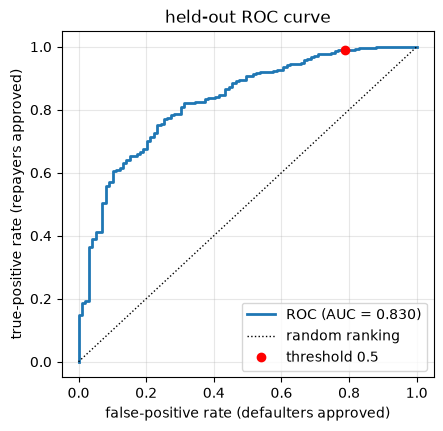

In [ ]:
clf_loan = LogisticRegression(fit_intercept=True, solver="lbfgs", random_state=SEED)
clf_loan.fit(X_loan_train, y_loan_train)

p_test = clf_loan.predict_proba(X_loan_test)[:, 1]

acc_floor = accuracy_score(y_loan_test, np.ones_like(y_loan_test))
acc_05 = accuracy_score(y_loan_test, p_test >= 0.5)
auc_test = float(roc_auc_score(y_loan_test, p_test))

print(f"approve everyone : accuracy {acc_floor:.3f}")
print(f"clf_loan at 0.5  : accuracy {acc_05:.3f}")
print(f"ROC-AUC          : {auc_test:.3f}")

fpr, tpr, _ = roc_curve(y_loan_test, p_test)
approve = p_test >= 0.5
plt.figure(figsize=(4.8, 4.5))
plt.plot(fpr, tpr, lw=2, label=f"ROC (AUC = {auc_test:.3f})")
plt.plot([0, 1], [0, 1], "k:", lw=1, label="random ranking")
plt.plot(approve[y_loan_test == 0].mean(), approve[y_loan_test == 1].mean(), "ro", label="threshold 0.5")
plt.xlabel("false-positive rate (defaulters approved)"); plt.ylabel("true-positive rate (repayers approved)")
plt.legend(loc="lower right"); plt.grid(alpha=0.3); plt.title("held-out ROC curve")
plt.show()

In [32]:
grader.check("q4")

q4 results: All test cases passed!

### 2b (autograded): precision, recall and F1 across thresholds

Accuracy and AUC each give one number; the desk needs to see what moving the cut does. The
lecture traced F1 against the threshold; do it here for all three metrics, on the held-out
half.

**Task.** For every `t` in `thresholds` (provided), approve the held-out applicants with
`p_test >= t` and compute, with `zero_division=0`:

1. `prec_t`, `rec_t`, `f1_t` — arrays of length `len(thresholds)` from `precision_score`,
   `recall_score` and `f1_score` (repaid = 1 is the positive class, sklearn's default).
2. `t_best_f1` — the threshold with the highest F1, as a `float`.

F1 is highest at t = 0.55, where the desk approves 96.5% of applicants


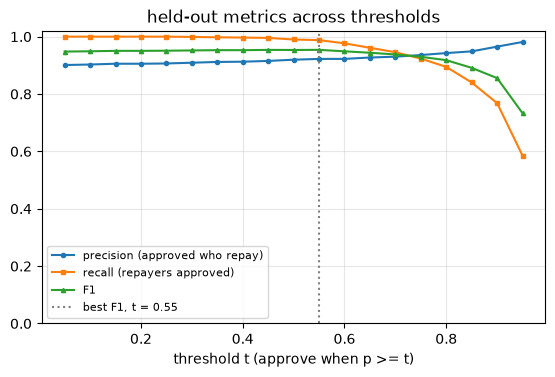

In [33]:
thresholds = np.round(np.arange(0.05, 1.0, 0.05), 2)

prec_t, rec_t, f1_t = [], [], []

for t in thresholds:
    approve = p_test >= t
    prec_t.append(precision_score(y_loan_test, approve))
    rec_t.append(recall_score(y_loan_test, approve))
    f1_t.append(f1_score(y_loan_test, approve))

t_best_f1 = float(thresholds[np.argmax(f1_t)])

print(f"F1 is highest at t = {t_best_f1:.2f}, where the desk approves {np.mean(p_test >= t_best_f1):.1%} of applicants")
plt.figure(figsize=(6.5, 3.8))
plt.plot(thresholds, prec_t, "o-", ms=3, label="precision (approved who repay)")
plt.plot(thresholds, rec_t, "s-", ms=3, label="recall (repayers approved)")
plt.plot(thresholds, f1_t, "^-", ms=3, label="F1")
plt.axvline(t_best_f1, color="gray", ls=":", label=f"best F1, t = {t_best_f1:.2f}")
plt.xlabel("threshold t (approve when p >= t)"); plt.ylim(0, 1.02)
plt.legend(fontsize=8, loc="lower left"); plt.grid(alpha=0.3); plt.title("held-out metrics across thresholds")
plt.show()

In [30]:
grader.check("q5")

q5 results: All test cases passed!

### 2c (autograded): the threshold the desk's costs choose

The desk gave you two rough figures for an average small-business loan:

- a **false approval** — the desk funds the loan and the member defaults — loses about
  **\$30,000** of principal after recoveries: $C_{FP} = 30{,}000$;
- a **false decline** — the desk turns away a member who would have repaid — loses about
  **\$7,500** of interest margin over the life of the loan: $C_{FN} = 7{,}500$.

The lecture's rule: approving is worth it exactly when $p\,C_{FN} > (1-p)\,C_{FP}$, that is when

$$
p > t^* = \frac{C_{FP}}{C_{FP} + C_{FN}}.
$$

**Task.**

1. `t_star` — the cost-optimal threshold, from `C_FP` and `C_FN`.
2. Write `cost_per_applicant(y_true, approve)`: the desk's total cost, `C_FP` times the
   number of approved applicants who defaulted plus `C_FN` times the number of declined
   applicants who would have repaid, **divided by the number of applicants**. `approve` is a
   boolean array. Return a `float` (dollars per applicant).
3. `cost_05` and `cost_tstar` — the held-out cost per applicant of `clf_loan` at threshold
   0.5 and at `t_star`.
4. `cost_t` — the held-out cost per applicant at every threshold in `thresholds` (an array),
   and `t_best_cost` — the threshold where it is lowest (`float`).
5. The fix you will hear for imbalanced data: refit with
   `clf_bal = LogisticRegression(penalty=None, class_weight="balanced", max_iter=1000)` on the
   training half, approve at its default threshold 0.5, and store the held-out cost per
   applicant in `cost_bal`.

In [ ]:
C_FP = 30_000.0   # false approval: principal lost when a funded loan defaults
C_FN = 7_500.0    # false decline: margin lost on a sound member turned away

t_star = 


def cost_per_applicant(y_true, approve):
    """Average dollar cost per applicant of an approve/decline decision."""
    ...


...

# The desk's view of each rule, on the held-out half.
p_bal = clf_bal.predict_proba(X_loan_test)[:, 1]
rules = {
    "approve everyone": np.ones_like(p_test, dtype=bool),
    "t = 0.5": p_test >= 0.5,
    f"best F1, t = {t_best_f1:.2f}": p_test >= t_best_f1,
    f"t* = {t_star:.2f}": p_test >= t_star,
    "balanced, t = 0.5": p_bal >= 0.5,
}
summary = pd.DataFrame({
    "approval rate": [a.mean() for a in rules.values()],
    "defaulters approved": [int(np.sum(a & (y_loan_test == 0))) for a in rules.values()],
    "repayers declined": [int(np.sum(~a & (y_loan_test == 1))) for a in rules.values()],
    "cost per applicant ($)": [cost_per_applicant(y_loan_test, a) for a in rules.values()],
}, index=list(rules))
print(summary.round(3).to_string())
print(f"\nAUC  clf_loan {roc_auc_score(y_loan_test, p_test):.3f}   clf_bal {roc_auc_score(y_loan_test, p_bal):.3f}")
print(f"intercept  clf_loan {clf_loan.intercept_[0]:.2f}   clf_bal {clf_bal.intercept_[0]:.2f}")

plt.figure(figsize=(6.5, 3.8))
plt.plot(thresholds, cost_t, "o-", ms=3)
for t, style, lab in [(0.5, ":", "t = 0.5"), (t_best_f1, "-.", "best F1"), (t_star, "--", "t*")]:
    plt.axvline(t, color="gray", ls=style, label=lab)
plt.axhline(cost_bal, color="red", lw=0.8, label="balanced, t = 0.5")
plt.xlabel("threshold t (approve when p >= t)"); plt.ylabel("cost per applicant ($)")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.title("the desk's expected cost on the held-out half")
plt.show()

**Discuss (participation):** a vendor pitching the desk a credit-scoring package says:
*"Your data is imbalanced — just switch on `class_weight="balanced"`. Then 0.5 works and you
never have to argue about costs."* Using your table, tell the desk what "balanced" actually
did to its decisions, and why you would still set the threshold from its two cost figures.

*(1-2 sentences here)*

In [ ]:
grader.check("q6")

<!-- BEGIN QUESTION -->

## Report out: what you would tell the lending desk

Write the two sentences you would put at the top of your memo to the lending desk: the
**recommendation** — which threshold to ship — and the **one caveat** they must hear. Then
pair-share with another team.

Use your Part 2 numbers:

- Which threshold do you recommend? Quote its approval rate and its cost per applicant next to
  0.5 and "balanced", and say which mistake the desk should fear more and why.
- $t^*$ rests on two rough cost figures. If the true margin on a sound loan were \$15,000
  rather than \$7,500, where would $t^*$ move? How sure must the desk be of its two numbers?
- The probabilities come from a simulator with the desk's default rate but not its applicants.
  What has to happen before this threshold decides a real application?
- If the desk also wants a middle band that goes to a loan officer, how many thresholds is
  that, and where do they sit in the picture from 1c?

Write the memo in the answer cell below — your team members' names, then **Recommendation:**
and **Caveat:** — and cite numbers from your notebook (`t_star`, `cost_tstar`, `cost_05`,
`cost_bal`, the approval rates in the table) where they support a claim.

**Pair-share (~3 min).** Compare memos with a neighboring team: same threshold? Same caveat?
Be ready to share one takeaway with the class.

> Staff will visit tables during this part. Be ready to explain your reasoning and to
> point at the cell that supports each claim.

_Type your answer here, replacing this text._

<!-- END QUESTION -->

## Wrap-up

Before you leave, each group should be able to answer, without notes:

1. Where is the sigmoid in "logistic regression is a linear model", and why is the line the
   desk sees through its applicants still a line?
2. Why was the score's accuracy at 0.5 not good news on a book where nine in ten repay, and
   what does AUC tell the desk that accuracy does not — and what does it not tell them?
3. Where did your threshold come from, and what did `class_weight="balanced"` do instead?

Submit the autograded parts (1a–2c) to Gradescope.